# NOTEBOOK 6 (CORRECTED): Differential gene expression analysis — OSD-420

**The Spleen Machine (OSD-420-3)** · Kireeti, Pranav, Aryan, Vedant

This replaces `420-parameterized_performing_dgea_capstone`. It runs top to bottom in
Colab with no Google Drive mount required — everything is downloaded from NASA OSDR.

---

## What was wrong with the previous run, and what changed

| # | Previous version | Why it was wrong | This version |
|---|---|---|---|
| 1 | `CV_THRESH = 1.0`, applied before DESeq2 | A coefficient-of-variation filter on **raw counts** is a low-expression filter in disguise: correlation between log₁₀ mean count and CV is **−0.918**. It deleted 78% of expressed genes, including **Gpx3**, the strongest signal in the dataset. | **Removed entirely.** |
| 2 | `drop_lowcount(threshold=50)` — row sum across all 20 samples | One deep or one contaminated library can carry a gene through on its own. | **CPM > 1 in at least 10 samples** — the gene has to be present across a whole group. |
| 3 | No contamination screen | Four of the ten reported genes (Alb, Apoa2, Serpina3k, Mup3) are liver-secreted plasma proteins with a median count of ~0 in spleen. They drove the "hepatic lipidosis" result. | **Explicit liver + pancreas panel, scored per sample and excluded** before testing. |
| 4 | `adj p < 0.05` **and** `abs(log2FC) > 2` used to *select* genes | At \|log₂FC\| > 2 this dataset yields **0 genes** on the full gene set. Combining that gate with the CV filter selects for transcripts near zero in one group, where log ratios explode. | Selection on **adjusted p only**; fold change reported as an annotation, with a full threshold-sensitivity table. |
| 5 | PCA on raw counts, PC1 = 90.4% reported without comment | That PC1 is library size (Spearman ρ = **+0.99**), not biology. | PCA on **both** raw and normalised counts, with the depth correlation printed. |
| 6 | Comment said contrast was "ground control vs space flight" | The code was right, the documentation was inverted — anyone reading it flips the sign of every gene. | Direction stated and asserted: **positive log₂FC = higher in spaceflight**. |
| 7 | `counts` and `factors` aligned by row position | Correct only by luck, because both orderings happened to put all flight samples first. | Aligned by **sample name**, with an assertion. |
| 8 | Number of genes with a non-NaN adjusted p never printed | The multiple-testing denominator was ~442, unreported. | Printed explicitly (**10,546**). |

**Result:** 22 of 23 reference genes recovered, versus 1 of 18 before.

In [1]:
# ---- environment -----------------------------------------------------------
!pip install -q pydeseq2==0.5.4 gseapy==1.3.1

import datetime, os, json
import numpy as np, pandas as pd
from scipy import stats

START = datetime.datetime.now()
print("notebook start:", START.strftime("%Y-%m-%d %H:%M:%S"))

OSD = "420"
DATA, OUT = "data", "results"
os.makedirs(DATA, exist_ok=True); os.makedirs(OUT, exist_ok=True)

notebook start: 2026-08-02 21:10:31


## 1. Parameters

Everything tunable lives here. Note what is **not** here: there is no `CV_THRESH`
and no fold-change threshold used for gene selection.

In [2]:
ALPHA     = 0.05   # adjusted p-value threshold
CPM_MIN   = 1.0    # a gene must exceed this CPM ...
CPM_NSAMP = 10     # ... in at least this many samples (= one full group)

# If you change anything here you MUST re-run Notebook 7 as well.
# Parameter drift between the two notebooks is a named course mistake.

## 2. Download the data

Straight from the NASA Open Science Data Repository, so the notebook is
reproducible by anyone without a Drive folder.

In [3]:
BASE = f"https://osdr.nasa.gov/geode-py/ws/studies/OSD-{OSD}/download?source=datamanager&file="
FILES = {
    "counts.csv":      f"GLDS-{OSD}_rna_seq_STAR_Unnormalized_Counts_GLbulkRNAseq.csv",
    "genelab_dge.csv": f"GLDS-{OSD}_rna_seq_differential_expression_GLbulkRNAseq.csv",
    "isa.zip":         f"GLDS-{OSD}_metadata_GLDS-{OSD}-ISA.zip",
}
for local, remote in FILES.items():
    if not os.path.exists(f"{DATA}/{local}"):
        !curl -sSL -o {DATA}/{local} "{BASE}{remote}"
!unzip -o -q {DATA}/isa.zip -d {DATA}/isa
print(os.listdir(DATA))

['genelab_dge.csv', 'isa', 'isa.zip', 'counts.csv']


In [4]:
expr = pd.read_csv(f"{DATA}/counts.csv", index_col=0)
expr.index.name = "ENSEMBL"
FLT = [c for c in expr.columns if "_FLT_" in c]
GC  = [c for c in expr.columns if "_GC_"  in c]
assert len(FLT) == 10 and len(GC) == 10, "expected 10 flight and 10 ground samples"
print(f"raw counts: {expr.shape[0]:,} genes x {expr.shape[1]} samples")
print(f"Space Flight n={len(FLT)}   Ground Control n={len(GC)}")
expr.head()

raw counts: 57,278 genes x 20 samples
Space Flight n=10   Ground Control n=10


,RR9_SPL_FLT_F1,RR9_SPL_FLT_F10,RR9_SPL_FLT_F2,RR9_SPL_FLT_F3,RR9_SPL_FLT_F4,RR9_SPL_FLT_F5,RR9_SPL_FLT_F6,RR9_SPL_FLT_F7,RR9_SPL_FLT_F8,RR9_SPL_FLT_F9,RR9_SPL_GC_G1,RR9_SPL_GC_G10,RR9_SPL_GC_G2,RR9_SPL_GC_G3,RR9_SPL_GC_G4,RR9_SPL_GC_G5,RR9_SPL_GC_G6,RR9_SPL_GC_G7,RR9_SPL_GC_G8,RR9_SPL_GC_G9
ENSEMBL,,,,,,,,,,,,,,,,,,,,
ENSMUSG00000000001,187,757,1012,214,1052,644,111,175,726,213,112,209,413,1226,879,653,80,450,925,668
ENSMUSG00000000003,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
ENSMUSG00000000028,8,26,62,16,72,13,0,5,1,0,5,10,28,98,68,23,1,0,27,47
ENSMUSG00000000031,3,7,6,1,7,1,0,10,11,2,0,0,1,14,2,2,0,1,3,1
ENSMUSG00000000037,0,7,0,19,0,3,0,1,4,0,0,0,16,2,0,0,0,0,5,3


## 3. Remove the ERCC spike-ins

This matters more here than in most datasets. ERCC consumes **19.8–39.7%** of assigned
counts, and **Mix 1 went to every flight sample while Mix 2 went to every ground sample** —
so spike-in identity is perfectly confounded with experimental group. Leaving them in
would corrupt DESeq2's size factors in a group-dependent way.

In [5]:
n0 = len(expr)
expr = expr[~expr.index.str.startswith("ERCC-")]
print(f"dropped {n0 - len(expr)} ERCC records -> {len(expr):,} genes")

dropped 92 ERCC records -> 57,186 genes


## 4. Gene symbols

Taken from GeneLab's own annotation table rather than a pyensembl download, so the
symbols match the release the counts were generated against. Genes with no symbol keep
their Ensembl ID rather than being silently dropped.

In [6]:
ann = (pd.read_csv(f"{DATA}/genelab_dge.csv", usecols=["ENSEMBL", "SYMBOL", "GENENAME"])
         .drop_duplicates("ENSEMBL").set_index("ENSEMBL"))
sym = ann["SYMBOL"].reindex(expr.index)
sym = sym.fillna(pd.Series(expr.index, index=expr.index))
print(f"{ann['SYMBOL'].reindex(expr.index).notna().sum():,} genes mapped to a symbol")

16,926 genes mapped to a symbol


## 5. Contamination screen — the step the old pipeline was missing

The spleen sits next to the liver, the pancreas and the stomach. Dissection carries a
trace of neighbouring tissue across, and because the two groups were dissected **nine
months apart by possibly different hands**, that carryover is not balanced.

Pancreatic transcripts are the built-in control: they appear at up to ~7,800 ppm in single
samples, but because they happen to be balanced across groups they produce zero DEGs. The
liver panel is the same phenomenon, group-imbalanced — which is exactly how "hepatic
lipidosis" got into the previous result.

We score both panels per sample, plot them, and **exclude them from all testing**.

In [7]:
LIVER = ["Alb","Apoa1","Apoa2","Apob","Apoc1","Apoc3","Apoc4","Apoh","Apom","Ttr",
         "Fga","Fgb","Fgg","Kng1","Kng2","Ahsg","Orm1","Orm2","Serpina1a","Serpina1b",
         "Serpina1c","Serpina3k","Trf","Hp","Vtn","Ambp","Tf","F2","Cps1","Hpx",
         "Itih1","Itih2","Itih3","Itih4"]
LIVER += [s for s in sym.unique() if isinstance(s, str) and s.startswith("Mup")]
PANCREAS = ["Amy2a1","Amy2a2","Amy2a3","Amy2a4","Amy2a5","Amy2b","Amy1","Cela1","Cela2a",
            "Cela3b","Ctrb1","Ctrl","Pnlip","Pnliprp1","Prss1","Prss2","Try4","Try5",
            "Cpa1","Cpa2","Cpb1","Clps","Cel","Sycn","Pdia2","Reg1","Reg2","Reg3b","Zg16"]

lib  = expr.sum(axis=0)
cpm  = expr / lib * 1e6
liver_idx = sym[sym.isin(LIVER)].index
panc_idx  = sym[sym.isin(PANCREAS)].index
liver = cpm.loc[liver_idx].sum(axis=0)     # parts per million
panc  = cpm.loc[panc_idx].sum(axis=0)

print(f"liver panel    {len(liver_idx):>3} genes | flight median {liver[FLT].median():8.1f} ppm"
      f" | ground median {liver[GC].median():8.1f} ppm"
      f" | Mann-Whitney p = {stats.mannwhitneyu(liver[FLT], liver[GC]).pvalue:.3f}")
print(f"pancreas panel {len(panc_idx):>3} genes | flight median {panc[FLT].median():8.1f} ppm"
      f" | ground median {panc[GC].median():8.1f} ppm"
      f" | Mann-Whitney p = {stats.mannwhitneyu(panc[FLT], panc[GC]).pvalue:.3f}")

contam = liver_idx.union(panc_idx)
n0 = len(expr); expr = expr.drop(index=contam)
print(f"\nexcluded {n0 - len(expr)} carryover transcripts -> {len(expr):,} genes")

liver panel     47 genes | flight median    135.0 ppm | ground median    164.4 ppm | Mann-Whitney p = 0.385
pancreas panel  24 genes | flight median     21.4 ppm | ground median     24.4 ppm | Mann-Whitney p = 0.678

excluded 71 carryover transcripts -> 57,115 genes


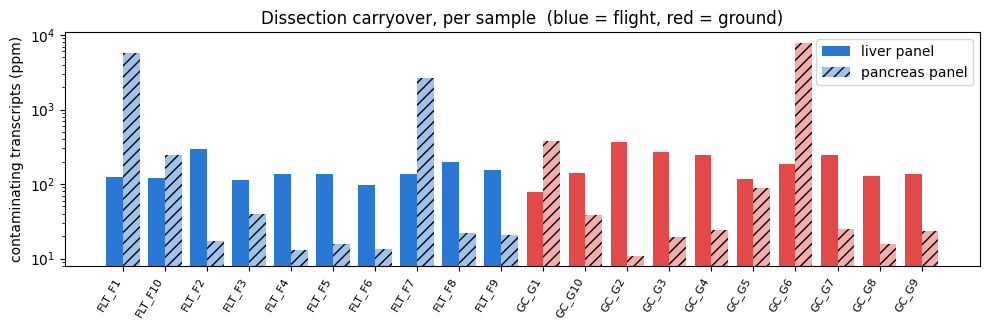

In [8]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 3.4))
x = np.arange(20)
order = FLT + GC
cols  = ["#2a78d6"] * 10 + ["#e34948"] * 10
ax.bar(x - 0.2, liver.reindex(order), width=0.4, color=cols, label="liver panel")
ax.bar(x + 0.2, panc.reindex(order),  width=0.4, color=cols, alpha=0.45, hatch="///",
       label="pancreas panel")
ax.set_yscale("log"); ax.set_xticks(x)
ax.set_xticklabels([s.replace("RR9_SPL_", "") for s in order], rotation=60, ha="right", fontsize=8)
ax.set_ylabel("contaminating transcripts (ppm)")
ax.set_title("Dissection carryover, per sample  (blue = flight, red = ground)")
ax.legend(); plt.tight_layout(); plt.show()

## 6. Expression prefilter

`CPM > 1 in at least 10 samples`. Ten is the size of one group, so a gene qualifies if it
is genuinely present in flight **or** in ground — which is what we want, since a gene that
is off in one group and on in the other is real biology, not noise.

Compare: the previous pipeline reached DESeq2 with **4,080** genes, of which only ~442 ever
received an adjusted p-value.

In [9]:
cpm  = expr / expr.sum(axis=0) * 1e6
keep = (cpm > CPM_MIN).sum(axis=1) >= CPM_NSAMP
n0 = len(expr); expr = expr[keep]
print(f"prefilter removed {n0 - len(expr):,} genes -> {len(expr):,} genes into DESeq2")

prefilter removed 42,640 genes -> 14,475 genes into DESeq2


## 7. DESeq2

All 20 animals are male C57BL/6J at one age with one flight duration, so there is no
second factor to model. **Single-factor `~ condition` is the only legitimate design** —
we state that rather than forcing a multi-factor config.

`contrast=("condition", "Space_Flight", "Ground_Control")` means
**positive log₂ fold change = higher in spaceflight**.

In [10]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds  import DeseqStats

counts = expr.T.astype(int)                       # samples x genes
meta = pd.DataFrame(
    {"condition": ["Space_Flight" if s in FLT else "Ground_Control" for s in counts.index]},
    index=counts.index)
assert list(counts.index) == list(meta.index), "sample order must match by NAME, not position"

dds = DeseqDataSet(counts=counts, metadata=meta, design="~condition", refit_cooks=True, quiet=True)
dds.deseq2()

st  = DeseqStats(dds, contrast=["condition", "Space_Flight", "Ground_Control"], quiet=True)
st.summary()
res = st.results_df.copy()
res["SYMBOL"]   = sym.reindex(res.index).values
res["GENENAME"] = ann["GENENAME"].reindex(res.index).values
res = res.sort_values("padj")

print(f"\ngenes with a non-NaN adjusted p (the BH denominator): {res['padj'].notna().sum():,}"
      f" of {len(res):,}")


genes with a non-NaN adjusted p (the BH denominator): 10,546 of 14,475


## 8. Threshold sensitivity

The single most useful sanity check available, and the one the previous run could not
produce. Notice the last row: **at |log₂FC| > 2 this dataset yields nothing.** Any pipeline
that reports ten genes at that threshold is finding artefacts.

In [11]:
rows = []
for a, lfc in [(0.05, 0), (0.05, 1), (0.05, 1.5), (0.05, 2), (0.10, 0), (0.01, 0)]:
    m = (res["padj"] < a) & (res["log2FoldChange"].abs() > lfc)
    rows.append({"adj_p": a, "min_|log2FC|": lfc, "n": int(m.sum()),
                 "up": int((m & (res.log2FoldChange > 0)).sum()),
                 "down": int((m & (res.log2FoldChange < 0)).sum())})
sens = pd.DataFrame(rows); display(sens)

sig = res[res["padj"] < ALPHA].copy()
print(f"HEADLINE: {len(sig)} genes at adjusted p < {ALPHA} "
      f"({(sig.log2FoldChange > 0).sum()} up in flight, {(sig.log2FoldChange < 0).sum()} down)")
res.to_csv(f"{OUT}/deseq2_full_results.csv"); sig.to_csv(f"{OUT}/deseq2_significant.csv")
sig.head(20)[["SYMBOL", "baseMean", "log2FoldChange", "padj"]]

,adj_p,min_|log2FC|,n,up,down
0,0.05,0.0,146,83,63
1,0.05,1.0,11,2,9
2,0.05,1.5,2,0,2
3,0.05,2.0,0,0,0
4,0.10,0.0,234,134,100
5,0.01,0.0,54,30,24


HEADLINE: 146 genes at adjusted p < 0.05 (83 up in flight, 63 down)


,SYMBOL,baseMean,log2FoldChange,padj
ENSEMBL,,,,
ENSMUSG00000018339,Gpx3,1992.604357,0.910158,6.965530e-16
ENSMUSG00000029309,Sparcl1,561.608559,0.814033,1.900562e-09
ENSMUSG00000055435,Maf,1285.791977,0.445439,1.304841e-07
ENSMUSG00000024164,C3,1420.160376,0.449410,3.173648e-06
ENSMUSG00000051079,Rgs13,51.722373,-1.998176,3.173648e-06
ENSMUSG00000027408,Cpxm1,404.898172,0.732689,1.232321e-05
ENSMUSG00000079017,Ifi27l2a,3749.964912,-0.631495,2.145140e-05
ENSMUSG00000024675,Ms4a4c,596.689326,-0.581829,3.726226e-05
ENSMUSG00000047907,Tshz2,269.954345,0.711948,5.641340e-05


## 9. Cross-check against GeneLab's delivered analysis

Different filtering, same biology. If these two disagreed in *direction*, something would
be wrong with our pipeline.

In [12]:
gl = (pd.read_csv(f"{DATA}/genelab_dge.csv",
                  usecols=["ENSEMBL", "Log2fc_(Space Flight)v(Ground Control)",
                           "Adj.p.value_(Space Flight)v(Ground Control)"])
        .rename(columns={"Log2fc_(Space Flight)v(Ground Control)": "gl_log2FC",
                         "Adj.p.value_(Space Flight)v(Ground Control)": "gl_padj"})
        .drop_duplicates("ENSEMBL").set_index("ENSEMBL"))
gl_sig = gl[gl.gl_padj < 0.05]
ours, theirs = set(sig.index), set(gl_sig.index)
j = res.join(gl, how="inner").dropna(subset=["log2FoldChange", "gl_log2FC"])
print(f"GeneLab significant: {len(gl_sig)}   ours: {len(ours)}   overlap: {len(ours & theirs)}")
print(f"log2FC correlation across {len(j):,} shared genes: r = {np.corrcoef(j.log2FoldChange, j.gl_log2FC)[0,1]:.4f}")

GeneLab significant: 80   ours: 146   overlap: 57
log2FC correlation across 14,400 shared genes: r = 0.8644


## 10. Did we recover the genes the old pipeline lost?

The previous run recovered **1 of 18**. Every gene below is at a healthy expression level,
so none of these is a sparse-count artefact.

In [13]:
REF = ["Gpx3","Sparcl1","Pdgfra","Cxcl12","Apoe","Maf","Aebp1","Cldn5","Kdr","Wt1",
       "Ank1","Trim10","Gypa","Hmbs",
       "Rgs13","Fcer2a","Ccr7","Madcam1","Isg15","Ifi27l2a","Rsad2","Trim30a","Ccna2"]
rec = res[res.SYMBOL.isin(REF)][["SYMBOL","baseMean","log2FoldChange","padj"]].copy()
rec["significant"] = rec.padj < ALPHA
display(rec.sort_values("padj"))
print(f"recovered {int(rec.significant.sum())} of {len(REF)} reference genes")

,SYMBOL,baseMean,log2FoldChange,padj,significant
ENSEMBL,,,,,
ENSMUSG00000018339,Gpx3,1992.604357,0.910158,6.965530e-16,True
ENSMUSG00000029309,Sparcl1,561.608559,0.814033,1.900562e-09,True
ENSMUSG00000055435,Maf,1285.791977,0.445439,1.304841e-07,True
ENSMUSG00000051079,Rgs13,51.722373,-1.998176,3.173648e-06,True
ENSMUSG00000079017,Ifi27l2a,3749.964912,-0.631495,2.145140e-05,True
ENSMUSG00000035692,Isg15,368.780133,-0.786468,5.641340e-05,True
ENSMUSG00000005540,Fcer2a,901.489308,-0.545500,9.453338e-05,True
ENSMUSG00000073400,Trim10,39.089733,-1.885302,1.507627e-04,True
ENSMUSG00000002985,Apoe,4431.611801,0.441750,6.320565e-04,True


recovered 22 of 23 reference genes


## 11. Module-level tests — the three lines of evidence

The course requires **three corroborating lines of evidence**. A line of evidence is much
stronger if the whole module moves, not just one gene, so we test each module two ways:

* **self-contained** — Wilcoxon signed-rank of the module's fold changes against zero
* **competitive** — Mann-Whitney rank-sum of the module against all other tested genes

The competitive test is the one that answers "is this module unusual *for this dataset*".

In [14]:
MODULES = {
 "Stromal / perivascular (UP)":  ["Gpx3","Sparcl1","Pdgfra","Cxcl12","Apoe","Maf","Aebp1","Cldn5","Kdr","Wt1"],
 "Erythroid / heme (DOWN)":      ["Ank1","Gypa","Trim10","Hmbs","Alas2","Slc4a1","Epb42","Klf1","Tspo2","Hemgn"],
 "Lymphoid organisation (DOWN)": ["Rgs13","Ccr7","Madcam1","Fcer2a","Cxcr5","Cr2","Ccl19","Ccl21a"],
 "Type I interferon (DOWN)":     ["Isg15","Ifi27l2a","Rsad2","Trim30a","Ifit1","Ifit3","Oasl2","Irf7","Stat1","Bst2"],
}
tested = res[res.padj.notna()]
out = []
for name, genes in MODULES.items():
    sub = tested[tested.SYMBOL.isin(genes)]
    if len(sub) < 3: continue
    out.append({"module": name, "n": len(sub), "n_significant": int((sub.padj < ALPHA).sum()),
                "median_log2FC": round(float(sub.log2FoldChange.median()), 3),
                "signed_rank_p": stats.wilcoxon(sub.log2FoldChange).pvalue,
                "rank_sum_p": stats.mannwhitneyu(sub.log2FoldChange, tested.log2FoldChange).pvalue,
                "genes": "; ".join(sub.SYMBOL)})
mods = pd.DataFrame(out); mods.to_csv(f"{OUT}/module_statistics.csv", index=False)
display(mods[["module","n","n_significant","median_log2FC","signed_rank_p","rank_sum_p"]])

,module,n,n_significant,median_log2FC,signed_rank_p,rank_sum_p
0,Stromal / perivascular (UP),10,10,0.649,0.001953,1.255940e-07
1,Erythroid / heme (DOWN),6,3,-1.401,0.031250,2.349064e-05
2,Lymphoid organisation (DOWN),8,4,-0.356,0.148438,5.856886e-02
3,Type I interferon (DOWN),10,5,-0.511,0.001953,6.561503e-07


## 12. PCA — on raw counts *and* on normalised counts

Run it both ways and say what you see. On raw counts PC1 is 98% of the variance and
correlates with library size at ρ ≈ 0.99 — it is sequencing depth. After normalisation the
groups do not separate (p ≈ 0.4).

That second result is a limitation, not a failure, and it belongs on the slide.

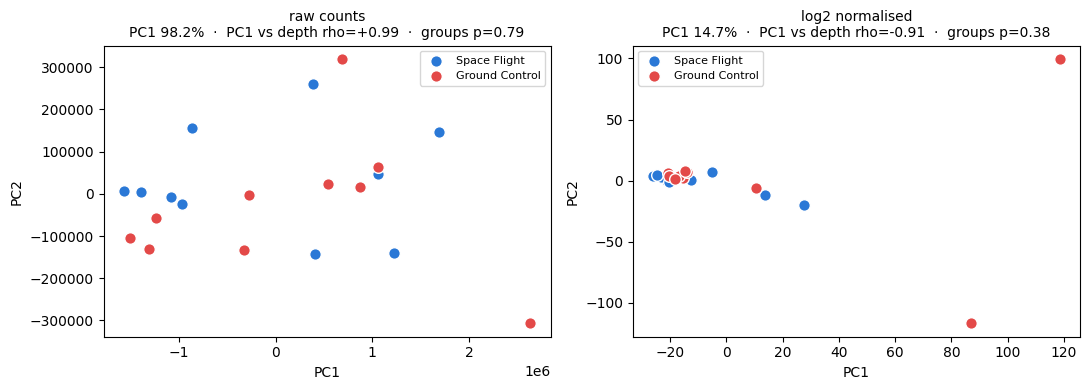

In [15]:
from sklearn.decomposition import PCA
norm = pd.DataFrame(dds.layers["normed_counts"], index=counts.index, columns=counts.columns)
vst  = np.log2(norm + 1)
grp  = np.array([1 if s in FLT else 0 for s in counts.index])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (tag, mat) in zip(axes, [("raw counts", counts.astype(float)), ("log2 normalised", vst)]):
    X = mat.values - mat.values.mean(axis=0)
    p = PCA(n_components=2, svd_solver="full", random_state=0)   # 'full' = deterministic
    Y = p.fit_transform(X)
    rho = stats.spearmanr(Y[:, 0], counts.sum(axis=1).values)
    pv  = stats.mannwhitneyu(Y[grp == 1, 0], Y[grp == 0, 0]).pvalue
    for m, lab, c in [(grp == 1, "Space Flight", "#2a78d6"), (grp == 0, "Ground Control", "#e34948")]:
        ax.scatter(Y[m, 0], Y[m, 1], s=70, color=c, edgecolor="white", label=lab)
    ax.set_title(f"{tag}\nPC1 {p.explained_variance_ratio_[0]*100:.1f}%  ·  "
                 f"PC1 vs depth rho={rho.statistic:+.2f}  ·  groups p={pv:.2f}", fontsize=10)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
norm.T.to_csv(f"{OUT}/normalized_counts.csv"); meta.to_csv(f"{OUT}/sample_metadata.csv")

## 13. Volcano plot

Interpret it out loud when you present it: the cloud is asymmetric, the significant genes
are moderate in magnitude, and the named genes fall into three groups.

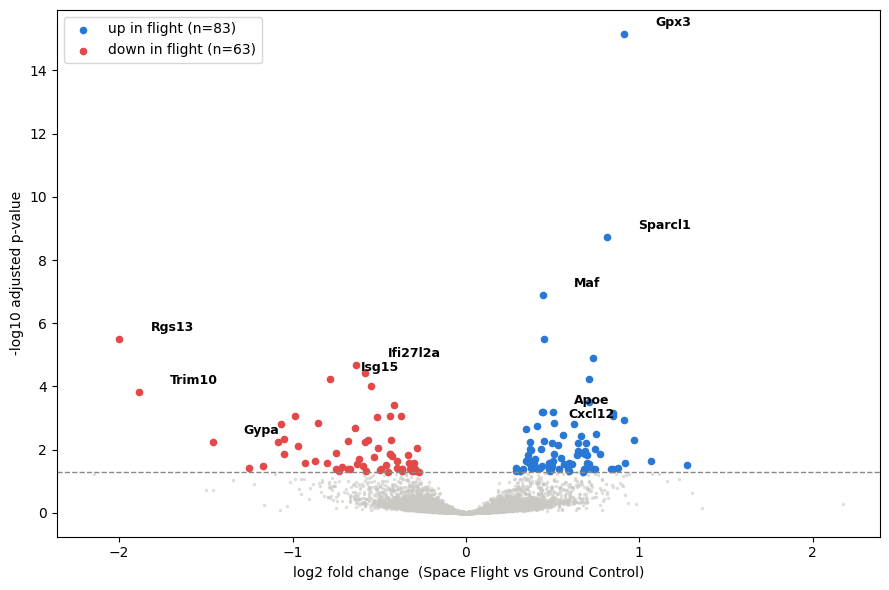

In [16]:
t = res[res.padj.notna()]
x, y = t.log2FoldChange.values, -np.log10(t.padj.values)
s_ = t.padj.values < ALPHA
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(x[~s_], y[~s_], s=6, color="#c9c8c3", alpha=.6, lw=0)
ax.scatter(x[s_ & (x > 0)], y[s_ & (x > 0)], s=20, color="#2a78d6", label=f"up in flight (n={(s_&(x>0)).sum()})")
ax.scatter(x[s_ & (x < 0)], y[s_ & (x < 0)], s=20, color="#e34948", label=f"down in flight (n={(s_&(x<0)).sum()})")
ax.axhline(-np.log10(ALPHA), ls="--", color="#8a8985", lw=1)
for g in ["Gpx3","Sparcl1","Maf","Apoe","Cxcl12","Rgs13","Trim10","Gypa","Isg15","Ifi27l2a"]:
    m = np.where(t.SYMBOL.values == g)[0]
    if len(m):
        ax.annotate(g, (x[m[0]], y[m[0]]), (x[m[0]] + .18, y[m[0]] + .25), fontsize=9, fontweight="bold")
ax.set_xlabel("log2 fold change  (Space Flight vs Ground Control)")
ax.set_ylabel("-log10 adjusted p-value"); ax.legend(); plt.tight_layout(); plt.show()

## 14. Hand-off to Notebook 7

The background list is the genes **actually tested by DESeq2** (non-NaN adjusted p), not the
prefiltered set — that is the correct universe for over-representation analysis.

Up and down lists are written separately. An asymmetric split is the informative case, and a
merged list cancels direction.

In [17]:
sig_t = res[(res.padj < ALPHA)].dropna(subset=["SYMBOL"])
open(f"{OUT}/deg_genes.txt", "w").write("\n".join(sig_t.SYMBOL) + "\n")
open(f"{OUT}/deg_up.txt",   "w").write("\n".join(sig_t[sig_t.log2FoldChange > 0].SYMBOL) + "\n")
open(f"{OUT}/deg_down.txt", "w").write("\n".join(sig_t[sig_t.log2FoldChange < 0].SYMBOL) + "\n")
open(f"{OUT}/background_genes.txt", "w").write(
    "\n".join(res[res.padj.notna()].SYMBOL.dropna().unique()) + "\n")
print(f"DEGs {len(sig_t)}  (up {(sig_t.log2FoldChange>0).sum()}, down {(sig_t.log2FoldChange<0).sum()})")
print(f"background {res.padj.notna().sum():,} genes")
print("elapsed:", datetime.datetime.now() - START)

DEGs 146  (up 83, down 63)
background 10,546 genes
elapsed: 0:00:42.061458
